# Phase 2: auditable, transposition-invariant training data

## tl;dr
Run top to bottom. This notebook audits **every extracted track folder**, then saves a new, immutable `phase2_dataset_v2` snapshot. Your existing audit, development notebook, v1 snapshot and checkpoints remain intact. **Executed result:** 1,372 folders audited; 4,446 accepted windows from 373 songs. The executed summary below reports split counts and exclusions.

The unit of supervision is **one chord per detected beat in a non-overlapping eight-bar melody window**. The requested product is a progression; the next notebook converts beat predictions into Roman-numeral segments with durations.

The extraction pipeline supplies **pseudo-labels**, not manually verified harmonic ground truth. Cleaning can establish timing and representation consistency; it cannot prove that an extracted melody note or chord is musically correct.

## Context & Methods

Your `02_phase2_dataset_audit` already checked inventory, key agreement, melody coverage, meters and chord alignment. Your `phase2_transformer_development` tested beat queries, temporal cross-attention, weighted cross entropy and melody sensitivity. We retain their strongest ideas: complete bars, eight-bar windows, duration-dominant targets, official artist-separated splits and explicit masks.

Changes here: reproducible paths and hashes; conservative note edits; **train-only multi-label genre vocabulary**; fixed root × quality output space; local, ordered melody features; unknown/ambiguous chords remain masked; no forced key snapping or gap filling.

### Key Assumptions

- A tonic and major/minor mode are available at inference. Normalized C-major/A-minor MIDI is also accepted. The model itself never sees the original key or absolute register.
- Transposition invariance does not mean discarding rhythm or contour. They often distinguish melodies with the same pitch classes. Four ordered slots per beat preserve coarse within-beat order; very fast ornaments are compressed.
- Roman roots use the pipeline's **chromatic semitones relative to tonic**, with major-scale degree names in both modes. Thus A minor's C major chord is `bIII:MAJ`. Chord quality is explicit (`i:MIN`, `V:DOM7`); inversions/extensions outside the submission vocabulary are not modeled.
- The strict first cohort requires melody/chord key agreement and high confidence from both. This uses chord evidence for **dataset selection only**, never model inputs or key selection. It can favor easy, tonic-heavy tracks; scores apply to this selected cohort.
- Unsupported/incomplete meters, uncertain keys, long gaps and insufficient labels are excluded with reasons. Genuine rests, leaps and chromatic tones remain. Source mixtures (vocal plus instrumental fallback) are measured, not hidden.
- Octave-error candidates are flagged but **not repaired by default**. Distinguishing a real leap from an error requires listening or stronger evidence.

### 1. Setup and explicit cleaning policy

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "datasets/mtg-jamendo/melody-chord-extraction-pipeline").is_dir())
NOTEBOOKS = PROJECT / "experiments/pasan/notebooks"
sys.path.insert(0, str(NOTEBOOKS))
SNAPSHOT = NOTEBOOKS / "phase2_dataset_v2"
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "axes.axisbelow": True})
BLUE, GOLD, PINK = "#2864A0", "#B17A12", "#AB5178"
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_rows", 16)

In [2]:
from dataclasses import asdict
from phase2_harmony.data import (CleanConfig, build_snapshot, load_snapshot, verify_snapshot,
                                LABELS, FAMILIES, FILES, melody_features, file_hash)
CONFIG = CleanConfig()
display(pd.Series(asdict(CONFIG), name="value").to_frame())
print("Source:", PROJECT / "datasets/mtg-jamendo/melody-chord-extraction-pipeline/outputs")
print("Snapshot:", SNAPSHOT)
# Change SNAPSHOT to a new version if changing policy or source files.
metadata = build_snapshot(PROJECT, SNAPSHOT, CONFIG)
arrays, examples, metadata = load_snapshot(SNAPSHOT)
track_audit = pd.read_csv(SNAPSHOT / "track_audit.csv")
window_audit = pd.read_parquet(SNAPSHOT / "window_audit.parquet")
display(pd.Series(metadata["summary"], name="observed").to_frame())

,value
window_bars,8
min_note_seconds,0.03
min_melody_coverage,0.5
min_note_count,10
max_gap_beats,16.0
min_chord_coverage,0.8
min_chord_dominance,0.65
min_valid_target_fraction,0.7
strict_key,True
repair_isolated_octaves,False


Source: /Users/praise/Developer/vocal-harmonization/datasets/mtg-jamendo/melody-chord-extraction-pipeline/outputs
Snapshot: /Users/praise/Developer/vocal-harmonization/experiments/pasan/notebooks/phase2_dataset_v2


,observed
folders,1372
candidate_tracks,377
accepted_tracks,373
accepted_windows,4446
rejected_windows,748
splits,"{'train': 2463, 'test': 1031, 'validation': 952}"


## Data
### 2. Inventory, key reliability and exclusions
`track_audit.csv` covers all folders, including missing and unreadable inputs. Structural/timing checks run on every complete track before key filtering. `window_audit.parquet` covers windows from the strict key cohort; windows are accepted or carry one or more reasons. Source freshness checks validate the melody→key→Roman/chord comparison chain.

,status,reason,tracks
0,candidate,NaN,377
1,rejected,ValueError:missing_key,1
2,rejected,key_uncertain_or_disagree,992
3,rejected,"missing:melody,beats,roman,key,comparison",2


agreement,agree,disagree,insufficient_evidence
melody_confidence,,,
high,463,231,4
low,109,242,13
medium,118,185,4


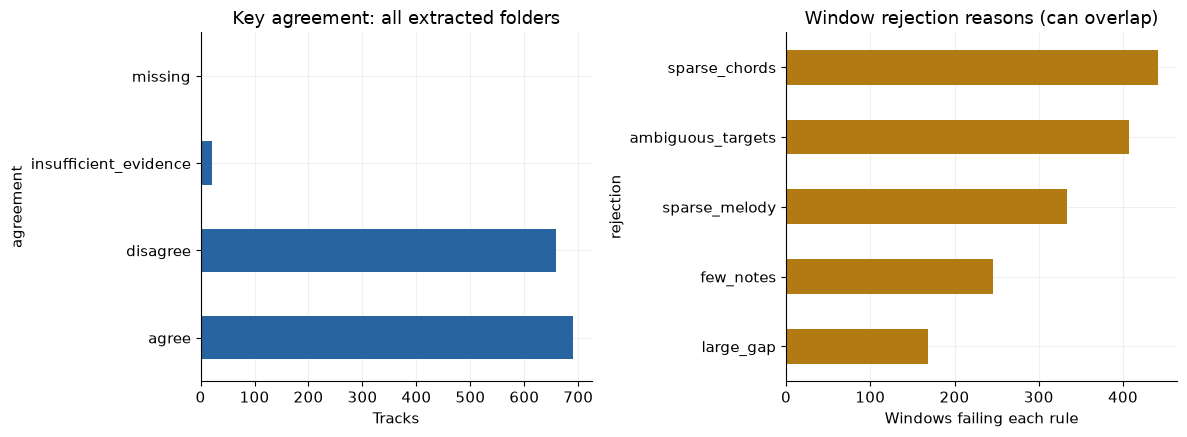

Complete strict-key candidates: 377
Window retention: 85.6%


In [3]:
display(track_audit.groupby(["status", "reason"], dropna=False).size().rename("tracks").reset_index())
display(pd.crosstab(track_audit.melody_confidence, track_audit.agreement))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
track_audit.agreement.fillna("missing").value_counts().plot.barh(ax=axes[0], color=BLUE)
axes[0].set(title="Key agreement: all extracted folders", xlabel="Tracks")
reasons = window_audit.loc[~window_audit.accepted, "rejection"].str.split(",").explode().value_counts()
reasons.sort_values().plot.barh(ax=axes[1], color=GOLD)
axes[1].set(title="Window rejection reasons (can overlap)", xlabel="Windows failing each rule")
plt.tight_layout(); plt.show()
print("Complete strict-key candidates:", (track_audit.status == "candidate").sum())
print("Window retention:", f"{window_audit.accepted.mean():.1%}")

### 3. Cleaning edits, pitch leaps, gaps and extraction sources

,events
action,
flag_octave,611


,track_id,onset_sec,pitch,action
0,track_0024017,44.80990,50,flag_octave
1,track_0024017,48.35990,50,flag_octave
2,track_0024017,51.81979,50,flag_octave
3,track_0024017,55.50000,50,flag_octave
4,track_0024017,59.26979,50,flag_octave
5,track_0024017,62.39010,50,flag_octave
6,track_0024017,110.11979,50,flag_octave
7,track_0024017,111.31979,50,flag_octave


,raw_notes,cleaned_notes,overlapping_notes,large_leaps,octave_candidates,vocal_fraction
count,1370.000,1370.000,1370.0,1370.000,1370.000,1370.000
mean,498.442,498.442,0.0,7.745,0.446,0.496
std,312.065,312.065,0.0,13.671,5.422,0.300
min,13.000,13.000,0.0,0.000,0.000,0.000
25%,316.250,316.250,0.0,1.000,0.000,0.248
50%,447.000,447.000,0.0,4.000,0.000,0.541
75%,609.500,609.500,0.0,9.000,0.000,0.731
max,2730.000,2730.000,0.0,240.000,183.000,1.000


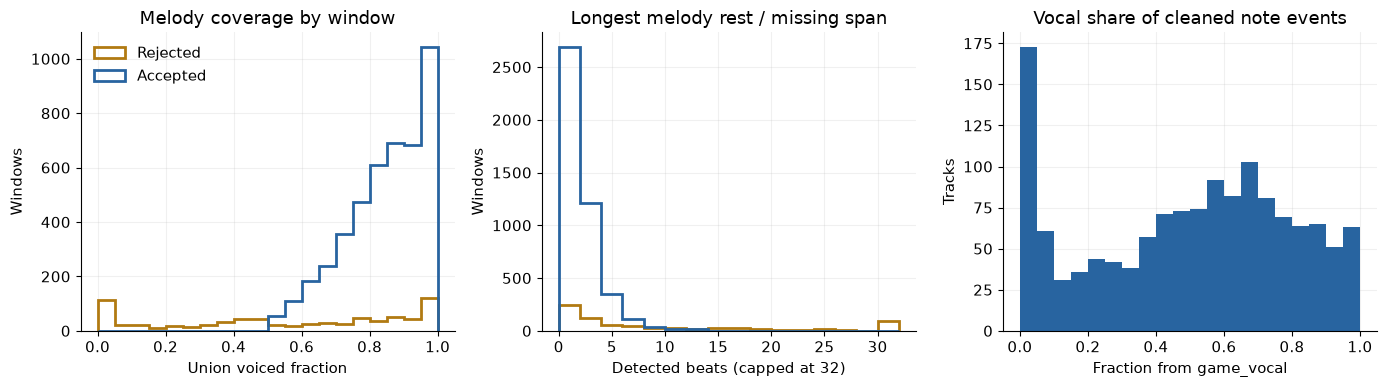

In [4]:
actions = pd.read_json(SNAPSHOT / "note_actions.jsonl", lines=True) if (SNAPSHOT / "note_actions.jsonl").stat().st_size else pd.DataFrame()
if len(actions):
    display(actions.action.value_counts().rename("events").to_frame())
    display(actions.head(8))
else:
    print("No event edits or octave candidates under this policy.")
display(track_audit[["raw_notes", "cleaned_notes", "overlapping_notes", "large_leaps", "octave_candidates", "vocal_fraction"]].describe().round(3))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for accepted, color, label in [(False, GOLD, "Rejected"), (True, BLUE, "Accepted")]:
    part = window_audit[window_audit.accepted == accepted]
    axes[0].hist(part.coverage, bins=np.linspace(0,1,21), histtype="step", linewidth=2, color=color, label=label)
    axes[1].hist(part.gap_beats.clip(upper=32), bins=np.arange(0,34,2), histtype="step", linewidth=2, color=color)
axes[0].set(title="Melody coverage by window", xlabel="Union voiced fraction", ylabel="Windows")
axes[0].legend(frameon=False)
axes[1].set(title="Longest melody rest / missing span", xlabel="Detected beats (capped at 32)", ylabel="Windows")
track_audit.vocal_fraction.dropna().plot.hist(bins=20, ax=axes[2], color=BLUE)
axes[2].set(title="Vocal share of cleaned note events", xlabel="Fraction from game_vocal", ylabel="Tracks")
plt.tight_layout(); plt.show()

### 4. Splits and train-only genre coverage
Official `split_0` is retained (the manifest calls the middle split `validation`). Each artist must occur in exactly one split. Exact normalized **melody + chord window** duplicates across splits are quarantined; this does not establish the absence of alternate recordings, covers, or near-duplicate audio. Rare/unseen genres map to an explicit unknown token; multiple known genres are all retained.

,windows,songs,artists
split,,,
test,1031,79,31
train,2463,196,73
validation,952,98,29


Genre vocabulary (training songs only, minimum three songs): ['<unknown>', 'alternative', 'ambient', 'blues', 'chanson', 'classical', 'dance', 'electronic', 'electropop', 'experimental', 'folk', 'funk', 'gothic', 'grunge', 'hardrock', 'hiphop', 'house', 'improvisation', 'indie', 'instrumentalrock', 'jazz', 'metal', 'newage', 'pop', 'popfolk', 'poprock', 'postrock', 'progressive', 'psychedelic', 'punkrock', 'reggae', 'rock', 'soul', 'soundtrack', 'swing', 'triphop', 'world', 'worldfusion']
train unknown-only genre windows: 0.2%
validation unknown-only genre windows: 2.7%
test unknown-only genre windows: 1.4%


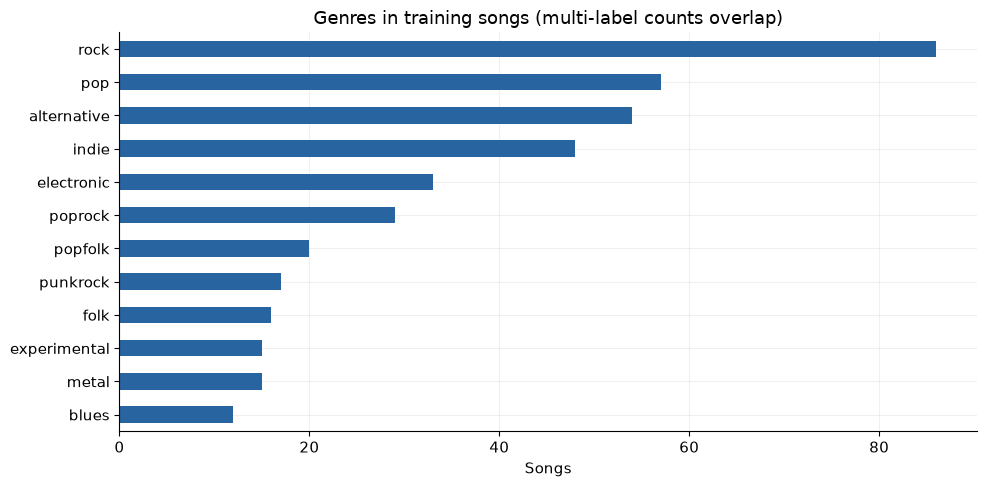

In [5]:
assert examples.groupby("artist_id").split.nunique().max() == 1
assert examples.groupby("track_id").split.nunique().max() == 1
assert not examples.duplicated(["track_id", "start_sec", "end_sec"]).any()
assert examples.groupby("content_hash").split.nunique().max() == 1
display(examples.groupby("split").agg(windows=("track_id","size"), songs=("track_id","nunique"), artists=("artist_id","nunique")))
print("Genre vocabulary (training songs only, minimum three songs):", metadata["genre_vocab"])
for split in ["train","validation","test"]:
    ix = examples.split.to_numpy() == split
    print(split, "unknown-only genre windows:", f"{arrays['genres'][ix,0].mean():.1%}")
train_tracks = examples[examples.split == "train"].drop_duplicates("track_id")
from collections import Counter
genre_counts = Counter(g for gs in train_tracks.genres for g in gs)
fig, ax = plt.subplots(figsize=(10, 5))
pd.Series(genre_counts).nlargest(12).sort_values().plot.barh(ax=ax, color=BLUE)
ax.set(title="Genres in training songs (multi-label counts overlap)", xlabel="Songs")
plt.tight_layout(); plt.show()

## Results
### 5. Target imbalance and vocabulary coverage
Fixed output space: 12 chromatic roots × nine supported qualities = 108 Roman-numeral classes. Rare qualities are preserved. The factorized model can share root/quality evidence even when a particular combination is absent from training. `N`, unsupported chords and ambiguous beat boundaries are ignored in the loss; they are never relabeled as tonic.

The target duration threshold is measured against the **entire beat**, including unannotated/no-chord spans. We do not snap chord boundaries to beats. Root/quality accuracy in the next notebook supplements exact chord accuracy.

train valid labels: 69172 / 72936 observed classes: 60
validation valid labels: 27610 / 28808 observed classes: 39
test valid labels: 28600 / 30112 observed classes: 39


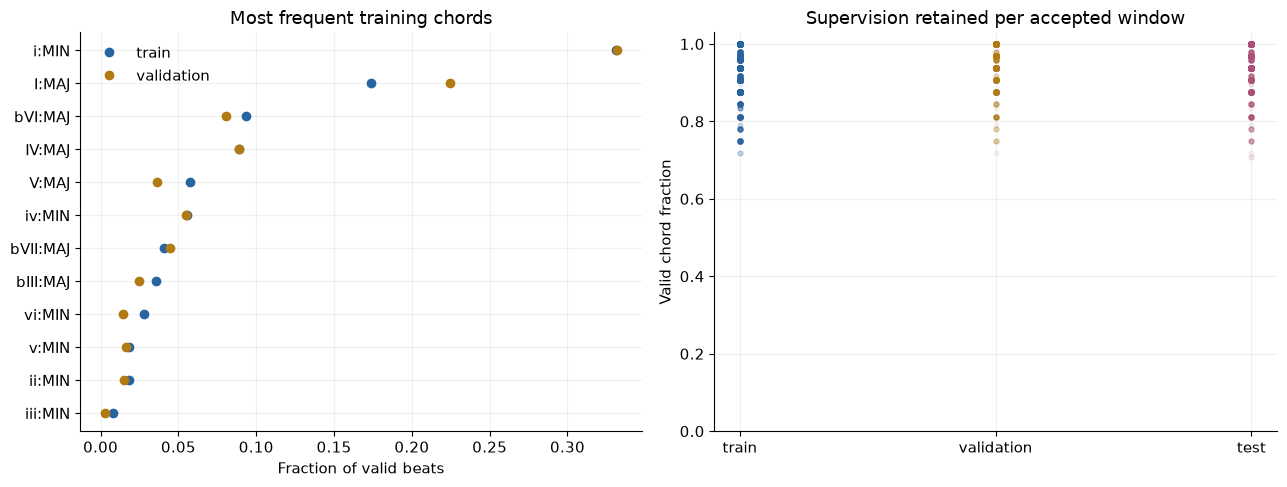

validation labels with unseen root-quality combination: 10 (0.04% of valid beats)
test labels with unseen root-quality combination: 0 (0.00% of valid beats)


In [6]:
counts = {}
for split in ["train", "validation", "test"]:
    y = arrays["y"][examples.split.to_numpy() == split]
    counts[split] = np.bincount(y[y>=0], minlength=len(LABELS))
    real = arrays["lengths"][examples.split.to_numpy() == split].sum()
    print(split, "valid labels:", int((y>=0).sum()), "/", real,
          "observed classes:", int((counts[split]>0).sum()))
top = np.argsort(counts["train"])[-12:]
fig, axes = plt.subplots(1,2,figsize=(13,5))
for split,color in [("train",BLUE),("validation",GOLD)]:
    values = counts[split] / counts[split].sum()
    axes[0].plot(values[top], np.arange(len(top)), "o", label=split, color=color)
axes[0].set_yticks(np.arange(len(top)), [LABELS[i] for i in top])
axes[0].set(title="Most frequent training chords", xlabel="Fraction of valid beats")
axes[0].legend(frameon=False)
for split,color in [("train",BLUE),("validation",GOLD),("test",PINK)]:
    subset=examples[examples.split==split]
    axes[1].scatter([split]*len(subset), subset.valid_target_fraction, alpha=.07, color=color, s=12)
axes[1].set(title="Supervision retained per accepted window", ylabel="Valid chord fraction", ylim=(0,1.03))
plt.tight_layout(); plt.show()
unseen = (counts["train"] == 0)
for split in ["validation","test"]:
    print(split, "labels with unseen root-quality combination:", int(counts[split][unseen].sum()),
          f"({counts[split][unseen].sum()/counts[split].sum():.2%} of valid beats)")

### 6. Inspect local order and one aligned example

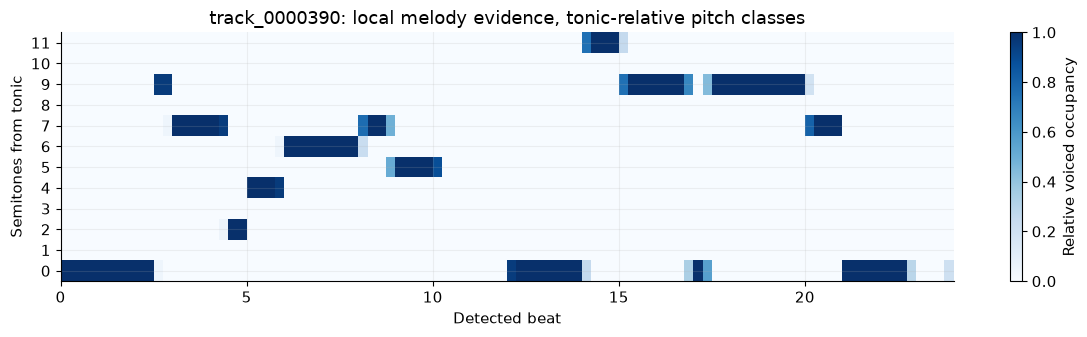

,beat,reference
0,0,I:MAJ
1,1,I:MAJ
2,2,I:MAJ
3,3,I:MAJ
4,4,I:MAJ
5,5,I:MAJ
6,6,ii:MIN
7,7,V:MAJ
8,8,V:MAJ
9,9,MASKED


Transposition and global octave invariance: passed


In [7]:
sample_index = int(examples[examples.split == "train"].index[0])
w = examples.iloc[sample_index]
x, y = arrays["x"][sample_index], arrays["y"][sample_index]
n = int(arrays["lengths"][sample_index])
# Reassemble the four chronological pitch-class slots per beat.
chromagram = np.concatenate([x[:n, 15*j:15*j+12][:,None,:] for j in range(4)], axis=1).reshape(n*4,12).T
fig, ax = plt.subplots(figsize=(12,3.5))
im=ax.imshow(chromagram, origin="lower", aspect="auto", extent=(0,n, -.5,11.5), cmap="Blues", vmin=0,vmax=1)
ax.set(title=f"{w.track_id}: local melody evidence, tonic-relative pitch classes", xlabel="Detected beat", ylabel="Semitones from tonic", yticks=range(12))
fig.colorbar(im,ax=ax,label="Relative voiced occupancy")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"beat":np.arange(n),"reference":[LABELS[v] if v>=0 else "MASKED" for v in y[:n]]}).head(16))
# Invariance is checked over a tonic wrap and multiple octaves.
notes = [{"onset_sec":i*.5,"offset_sec":(i+1)*.5,"pitch":p} for i,p in enumerate([71,73,78,70])]
base = melody_features(notes,[0,.5,1,1.5,2],11)
for shift in [-24,-11,1,7,12,25]:
    shifted=[{**note,"pitch":note["pitch"]+shift} for note in notes]
    np.testing.assert_allclose(base,melody_features(shifted,[0,.5,1,1.5,2],(11+shift)%12))
print("Transposition and global octave invariance: passed")

### 7. Snapshot verification and portable outputs

In [8]:
verify_snapshot(SNAPSHOT, verify_raw=True, project_root=PROJECT)
assert arrays["x"].shape[-1] == 77
assert np.isfinite(arrays["x"]).all()
assert arrays["confidence"][arrays["y"]>=0].min() >= CONFIG.min_chord_dominance - 1e-6
display(pd.DataFrame([{"file":p.name,"MB":p.stat().st_size/1e6} for p in sorted(SNAPSHOT.iterdir())]).round(3))
print("Verified source hashes:", len(metadata["raw_sha256"]))
print("Verified snapshot hashes:", len(metadata["files_sha256"]))

,file,MB
0,cleaned_notes.jsonl,18.467
1,examples.parquet,0.973
2,features.npz,2.724
3,metadata.json,0.955
4,note_actions.jsonl,0.055
5,track_audit.csv,0.225
6,window_audit.parquet,0.541


Verified source hashes: 8221
Verified snapshot hashes: 6


## Takeaways
The saved snapshot includes clean feature arrays (`features.npz`), per-window metadata and boundaries (`examples.parquet`), full window/track audits, cleaned note events, individual edit/flag records and hashes. It is reloadable without the raw audio. Rerunning with unchanged inputs verifies and reuses it; changed inputs or policy require a new version.

This is a conservative structural cleanup, **not a claim that every off-note or erroneous chord has been corrected**. Listen to flagged octave candidates, low-vocal-share tracks and high-overlap tracks before enabling repairs. Do not fill multi-beat gaps or force notes to the diatonic scale. The next notebook determines whether a model learns melody-dependent harmony beyond the mode-only baseline.

Useful follow-up data experiments: compare `strict_key=False` in a separate snapshot; compare vocal-only windows against the current mixed melody; manually annotate a small held-out listening set. Keep the current test split frozen while choosing these experiments from validation evidence.